# Modelo de Ising — Análisis preliminar

En esta notebook vamos a estudiar **termalización y autocorrelaciones** antes de elegir los parámetros de nuestras simulaciones definitivas de la guía 4.

La idea es aprovechar el mismo algoritmo de Metropolis que ya validamos, pero guardar ahora series temporales completas de energía y magnetización. Compararemos configuraciones iniciales ordenadas y aleatorias, y estimaremos los tiempos de autocorrelación relevantes para las incertidumbres estadísticas.

**Importante:** estos son estudios exploratorios. No vamos a decidir un tiempo de termalización mirando una sola trayectoria, ni suponer que guardar una configuración cada cierto número de MCS la convierte en independiente.

## 1. Generación de datos

Desde la raíz del repositorio, compilamos:

```bash
g++ -std=c++17 -O2 -Wall -Wextra main.cpp -o ising_sim
```

El modo preliminar acepta una semilla, el tamaño de red, la temperatura, la condición inicial, la cantidad total de barridos y el intervalo de guardado. Por ejemplo:

```bash
./ising_sim 12345 --prelim 16 2.26918531 random 20000 1
./ising_sim 67890 --prelim 16 2.26918531 ordered 20000 1
```

Cada combinación de parámetros tiene un nombre de CSV diferente en `preliminar_data/`. **Si repetimos exactamente los mismos parámetros y semilla, el archivo correspondiente se sobrescribe**; para conservar realizaciones diferentes usamos semillas diferentes. Cada CSV contiene `MCS`, `Energy_per_spin` y `Mag_per_spin`, incluyendo la configuración inicial (`MCS=0`). Un MCS representa **N intentos de inversión con elección aleatoria del sitio**, no necesariamente una visita a cada sitio.

Comenzaremos con corridas piloto; luego aumentaremos los tiempos en los casos que lo requieran (especialmente cerca de $T_c$ y para $L$ grandes). Por ahora usamos $J=1$, $B=0$.

Para comparar las condiciones iniciales, usamos **semillas distintas**: las trayectorias no deben coincidir punto por punto; sus observables deben ser estadísticamente compatibles tras la relajación.

## 2. Librerías y lectura de datos

Primero localizamos las series temporales disponibles. La notebook está pensada para ejecutarse desde la **raíz del repositorio**, donde también se encuentra `main.cpp`.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("preliminar_data")
GRAPH_DIR = Path("preliminar_graphs")
SAVE_FIGURES = False  # Cambiar a True si queremos guardar las figuras.

TC_EXACT = 2.0 / np.log(1.0 + np.sqrt(2.0))
print(f"Temperatura crítica exacta (J=k_B=1): Tc = {TC_EXACT:.8f}")

Temperatura crítica exacta (J=k_B=1): Tc = 2.26918531


In [2]:
pattern = re.compile(
    r"prelim_L=(?P<L>\d+)_T=(?P<T>\d+(?:\.\d+)?)_init=(?P<initial>random|ordered)_seed=(?P<seed>\d+)\.csv"
)

records = []
for path in sorted(DATA_DIR.glob("prelim_*.csv")):
    match = pattern.fullmatch(path.name)
    if match:
        info = match.groupdict()
        records.append({
            "L": int(info["L"]), "T": float(info["T"]),
            "initial": info["initial"], "seed": int(info["seed"]),
            "path": path,
        })

files = pd.DataFrame(records, columns=["L", "T", "initial", "seed", "path"])
if files.empty:
    print("Todavía no hay series preliminares. Ejecutá los comandos de la sección 1.")
else:
    display(files.drop(columns="path"))

,L,T,initial,seed
0,128,2.269185,ordered,67890
1,128,2.269185,random,12345
2,16,2.269185,ordered,67890
3,16,2.269185,random,12345
4,200,1.500000,ordered,67890
5,200,1.500000,random,12345
6,200,2.269185,ordered,67890
7,200,2.269185,random,12345
8,200,3.000000,ordered,67890
9,200,3.000000,random,12345


### Revisión rápida de los datos

Antes de analizar nada, comprobamos algunas restricciones físicas. A campo nulo, con $J=1$, para una red cuadrada con primeros vecinos se cumple $-2\leq e\leq 2$ y $|m|\leq 1$ en **cada configuración**. Esto sirve para detectar errores de energía como el que encontramos en las simulaciones anteriores.

In [3]:
REQUIRED = {"MCS", "Energy_per_spin", "Mag_per_spin"}

def load_series(path):
    df = pd.read_csv(path)
    if not REQUIRED.issubset(df.columns):
        raise ValueError(f"Faltan columnas en {path}")
    df = df.sort_values("MCS").reset_index(drop=True)
    if df.empty or df["MCS"].iloc[0] != 0:
        raise ValueError(f"La serie debe empezar en MCS=0: {path}")
    if not np.all(np.diff(df["MCS"].to_numpy()) > 0):
        raise ValueError(f"MCS duplicados o no crecientes en {path}")
    vals = df[["Energy_per_spin", "Mag_per_spin"]].to_numpy()
    if not np.isfinite(vals).all():
        raise ValueError(f"Datos no finitos en {path}")
    if (np.abs(df["Mag_per_spin"]) > 1.0 + 1e-10).any():
        raise ValueError(f"Magnetización fuera del rango físico en {path}")
    if (np.abs(df["Energy_per_spin"]) > 2.0 + 1e-9).any():
        raise ValueError(f"Energía fuera del rango físico (J=1, B=0) en {path}")
    return df

for path in files.get("path", []):
    load_series(path)
print(f"Series revisadas: {len(files)}")

Series revisadas: 14


## 3. Termalización: condición inicial ordenada vs. aleatoria

En equilibrio, los promedios termodinámicos no deberían depender de la condición inicial. Vamos a comparar $e(t)$ y $|m(t)|$ comenzando tanto de una red ordenada como de una red aleatoria.

Usamos $|m|$ porque a campo nulo el signo de $m$ puede cambiar por la simetría $\mathbb{Z}_2$. En un sistema finito, una transición de $m>0$ a $m<0$ no implica por sí misma pérdida del equilibrio.

**Cuidado:** que dos trayectorias se aproximen visualmente no prueba que el sistema haya termalizado; también vamos a observar qué ocurre al aumentar el tiempo simulado y repetir algunas semillas.

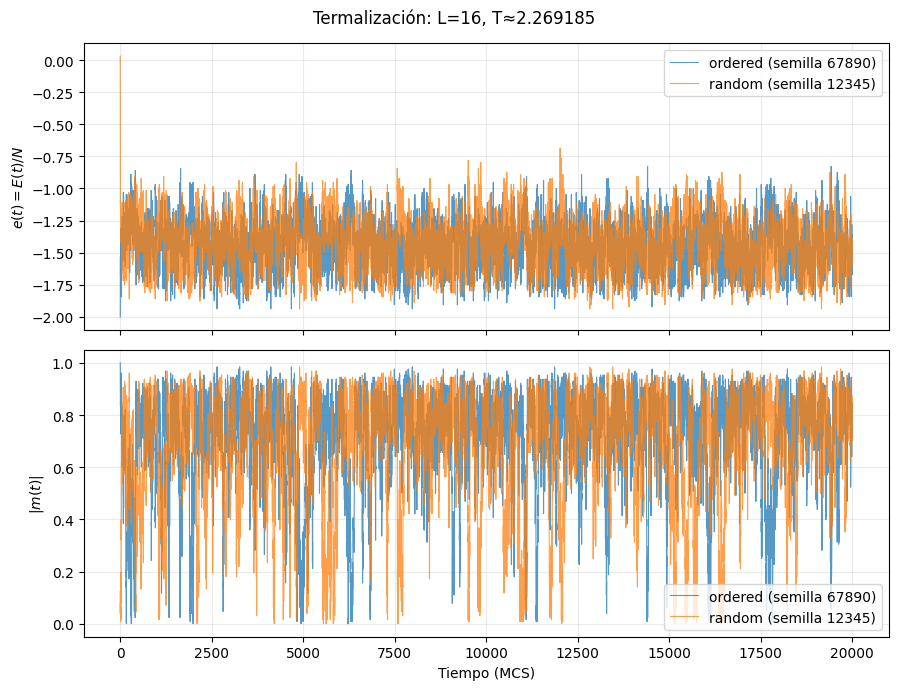

In [4]:
# Combinación de L y T a estudiar. Cambiaremos estas variables al pasar a otros tamaños.
L_VIEW = 16
T_VIEW = TC_EXACT
T_TOL = 5e-4

# Semillas de las DOS corridas que queremos comparar (actualizarlas para futuras corridas).
SEED_BY_INITIAL = {"ordered": 67890, "random": 12345}

subset = files[(files["L"] == L_VIEW) & ((files["T"] - T_VIEW).abs() < T_TOL)]
selected_runs = {}
for initial, seed in SEED_BY_INITIAL.items():
    choices = subset[(subset["initial"] == initial) & (subset["seed"] == seed)]
    if choices.empty:
        print(f"Falta la serie para L={L_VIEW}, T≈{T_VIEW:.6f}, {initial}, semilla={seed}")
    else:
        selected_runs[initial] = choices.iloc[0]

if selected_runs:
    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for initial, selected in selected_runs.items():
        df = load_series(selected["path"])
        label = f"{initial} (semilla {selected['seed']})"
        axes[0].plot(df["MCS"], df["Energy_per_spin"], lw=0.8, alpha=0.75, label=label)
        axes[1].plot(df["MCS"], df["Mag_per_spin"].abs(), lw=0.8, alpha=0.75, label=label)
    axes[0].set_ylabel(r"$e(t)=E(t)/N$")
    axes[1].set_ylabel(r"$|m(t)|$")
    axes[1].set_xlabel("Tiempo (MCS)")
    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(f"Termalización: L={L_VIEW}, T≈{T_VIEW:.6f}")
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / f"termalizacion_L={L_VIEW}_T={T_VIEW:.6f}.png", dpi=180)
    plt.show()


### Zoom del transitorio inicial

El gráfico completo comprime los primeros barridos. Repetimos la visualización para los **primeros 500 MCS** (sin volver a simular) y comparamos cómo se acercan ambas condiciones iniciales a una misma región de fluctuaciones. Que ambas trayectorias se crucen o tengan valores parecidos no constituye, por sí solo, una prueba de equilibrio.

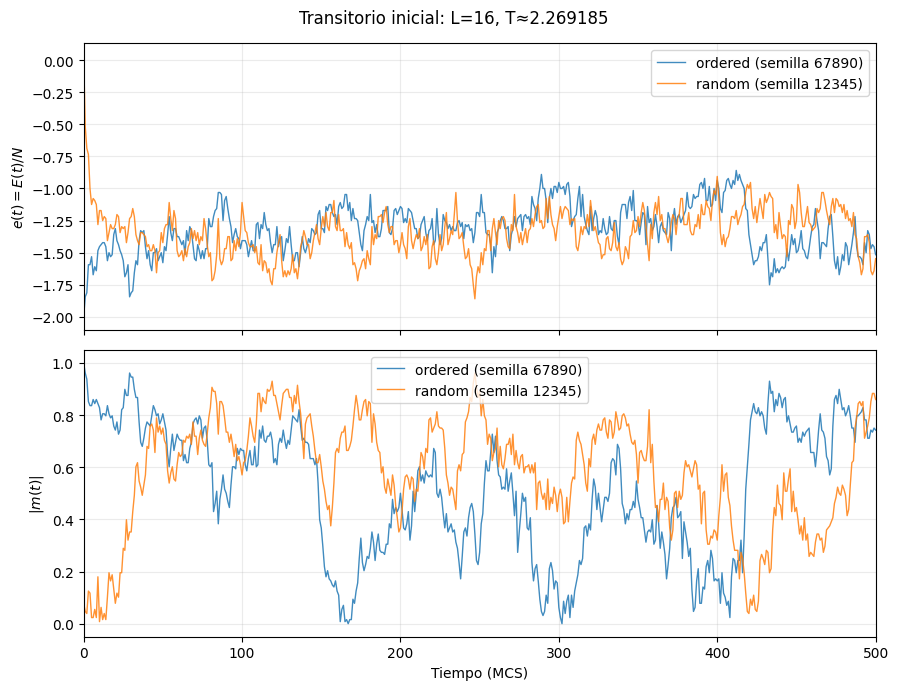

In [5]:
ZOOM_MCS = 500

if selected_runs:
    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    for initial, selected in selected_runs.items():
        df = load_series(selected["path"])
        df = df[df["MCS"] <= ZOOM_MCS]
        label = f"{initial} (semilla {selected['seed']})"
        axes[0].plot(df["MCS"], df["Energy_per_spin"], lw=1, alpha=0.85, label=label)
        axes[1].plot(df["MCS"], df["Mag_per_spin"].abs(), lw=1, alpha=0.85, label=label)
    axes[0].set_ylabel(r"$e(t)=E(t)/N$")
    axes[1].set_ylabel(r"$|m(t)|$")
    axes[1].set_xlabel("Tiempo (MCS)")
    for ax in axes:
        ax.set_xlim(0, ZOOM_MCS)
        ax.grid(alpha=0.25)
        ax.legend()
    fig.suptitle(f"Transitorio inicial: L={L_VIEW}, T≈{T_VIEW:.6f}")
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / f"termalizacion_zoom_L={L_VIEW}_T={T_VIEW:.6f}.png", dpi=180)
    plt.show()


## 4. Autocorrelaciones

Una vez descartado un tramo inicial que consideremos suficientemente largo, analizaremos la autocorrelación normalizada

$$
\rho_A(t)=\frac{\langle A(s)A(s+t)\rangle-\langle A\rangle^2}{\langle A^2\rangle-\langle A\rangle^2}.
$$

Nos interesa el **tiempo de autocorrelación integrado**

$$
\tau_{\mathrm{int},A}=\frac{1}{2}+\sum_{t=1}^\infty\rho_A(t),
$$

que determina el error del promedio. Por eso no alcanza con localizar el retardo en el que $\rho=1/e$: ese sería un tiempo característico exponencial, diferente de $\tau_{\mathrm{int}}$ en general.

Usaremos la energía y $|m|$. A baja temperatura, la magnetización con signo puede tener inversiones globales muy raras que dificultan mucho la estimación de su tiempo de autocorrelación. Calcularemos la autocorrelación con FFT para evitar el costo de evaluar cada retardo de forma independiente.

La suma infinita se trunca con una **ventana autoconsistente** aproximada $W\approx 5\tau_{\mathrm{int}}$. Si el resultado se acerca al máximo retardo disponible, hay que realizar una serie más larga; no tomar la cifra como definitiva.

In [6]:
def autocorrelation_fft(x, max_lag=None):
    # Autocorrelación normalizada, calculada por FFT.
    x = np.asarray(x, dtype=float)
    n = len(x)
    if n < 10:
        raise ValueError("Serie demasiado corta")
    x = x - x.mean()
    var = np.mean(x**2)
    if var <= 1e-25:
        raise ValueError("El observable casi no fluctúa; no puede estimarse su autocorrelación")
    nfft = 1 << (2 * n - 1).bit_length()
    fx = np.fft.rfft(x, nfft)
    corr = np.fft.irfft(fx * fx.conj(), nfft)[:n].real
    corr = corr / np.arange(n, 0, -1)  # Normalización por pares disponibles en cada retardo.
    rho = corr / corr[0]
    if max_lag is not None:
        rho = rho[:max_lag + 1]
    return rho


def integrated_time(rho, c=5.0):
    # Estimación preliminar mediante ventana autoconsistente.
    max_lag = len(rho) - 1
    window = 1
    tau = 0.5
    for _ in range(100):
        new_window = min(max(1, int(np.ceil(c * tau))), max_lag)
        new_tau = max(0.5, 0.5 + np.sum(rho[1:new_window + 1]))
        if new_window == window and abs(new_tau - tau) < 1e-9:
            break
        window, tau = new_window, new_tau
    return tau, window, (window < max_lag)

### Una primera estimación de $\tau_{\mathrm{int}}$

Elegimos una serie y descartamos un tiempo inicial. **`DISCARD_MCS` es una elección exploratoria**, no un tiempo de termalización ya validado: lo ajustaremos en función de los gráficos anteriores.

Para comparar tiempos entre series guardadas con distintos intervalos, convertimos $\tau_{\mathrm{int}}$ a MCS multiplicando por el intervalo de guardado. La estimación de muestras efectivas es

$$
N_{\mathrm{eff}}\approx \frac{N_{\mathrm{muestras}}}{2\tau_{\mathrm{int}}^{\mathrm{(muestras)}}}.
$$

Solo es una aproximación razonable si la cadena está en equilibrio y la estimación de $\tau_{\mathrm{int}}$ es estable.

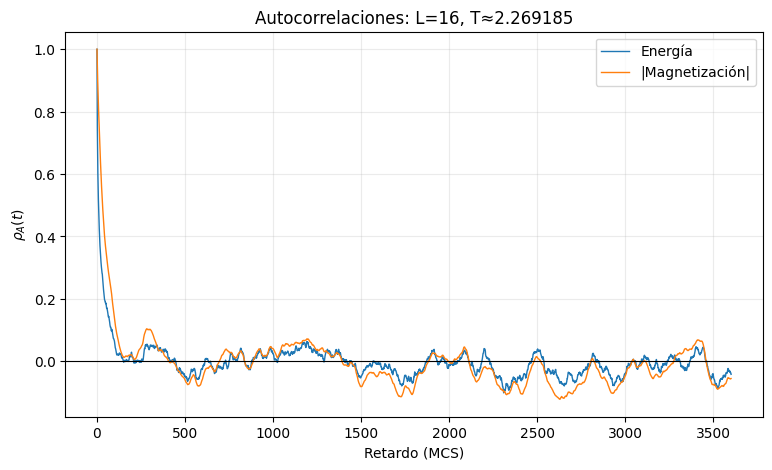

,Observable,tau_int (MCS),Ventana (MCS),N_eff aprox.,Ventana no saturada
0,Energía,24.57,123,366.34,True
1,|Magnetización|,46.88,235,192.00,True


In [7]:
DISCARD_MCS = 2000   # Exploratorio: NO usar como conclusión de termalización.
INITIAL_VIEW = "random"

if INITIAL_VIEW not in selected_runs:
    print("No hay datos para estudiar autocorrelaciones con estos parámetros.")
else:
    selected = selected_runs[INITIAL_VIEW]
    df = load_series(selected["path"])
    df = df[df["MCS"] >= DISCARD_MCS].copy()
    dts = np.diff(df["MCS"].to_numpy())
    if len(dts) < 20:
        print("Muy pocas muestras después de descartar el tramo inicial.")
    else:
        dt = int(pd.Series(dts).mode().iloc[0])
        # Excluir el último punto si se guardó excepcionalmente fuera de la grilla regular.
        df = df[df["MCS"] % dt == 0].copy()
        max_lag = min(len(df) // 5, 10000)
        fig, ax = plt.subplots(figsize=(9, 5))
        summary = []
        for name, values in {
            "Energía": df["Energy_per_spin"],
            "|Magnetización|": df["Mag_per_spin"].abs(),
        }.items():
            rho = autocorrelation_fft(values, max_lag=max_lag)
            tau, window, ok_window = integrated_time(rho)
            tau_mcs = tau * dt
            neff = len(df) / (2 * tau)
            summary.append({"Observable": name, "tau_int (MCS)": tau_mcs,
                            "Ventana (MCS)": window * dt,
                            "N_eff aprox.": neff,
                            "Ventana no saturada": ok_window})
            ax.plot(np.arange(len(rho)) * dt, rho, label=name, lw=1)
        ax.axhline(0, color="black", lw=0.8)
        ax.set(xlabel="Retardo (MCS)", ylabel=r"$\rho_A(t)$",
               title=f"Autocorrelaciones: L={L_VIEW}, T≈{T_VIEW:.6f}")
        ax.legend()
        ax.grid(alpha=0.25)
        plt.show()
        display(pd.DataFrame(summary).round(2))
        if not all(x["Ventana no saturada"] for x in summary):
            print("Atención: la ventana alcanzó el retardo máximo; repetir con una serie más larga.")

## 5. Comprobación de estabilidad: tiempo descartado y condición inicial

Para cada trayectoria estimamos el promedio, el error del promedio y el tiempo de autocorrelación integrado **después de descartar** 500, 1000, 2000 y 4000 MCS. Comparamos energía y $|m|$ entre las dos condiciones iniciales, siempre usando semillas distintas.

La incertidumbre preliminar del promedio se aproxima por

$$
\mathrm{SE}(\overline A)\simeq\sqrt{\frac{2\tau_{\mathrm{int},A}}{n}\,s_A^2},
$$

donde $\tau_{\mathrm{int},A}$ se expresa en **intervalos de medición**, $n$ es la cantidad de valores guardados y $s_A^2$ la varianza muestral. Esta fórmula supone equilibrio y una estimación razonable de $\tau_{\mathrm{int}}$. Los intervalos obtenidos con diferentes descartes se superponen, por lo que sus promedios **no son independientes**. Buscamos estabilidad y compatibilidad estadística, no coincidencia exacta ni un tiempo mínimo de termalización.

In [8]:
DISCARDS_MCS = [500, 1000, 2000, 4000]
MAX_LAG_MCS = 2000  # Límite exploratorio de la autocorrelación, expresado en MCS.

# Evita incluir un último punto guardado fuera del intervalo regular de medición.
def regular_series(path):
    df = load_series(path)
    gaps = np.diff(df["MCS"].to_numpy())
    if len(gaps) == 0:
        raise ValueError(f"Serie sin suficientes datos: {path}")
    dt = int(pd.Series(gaps).mode().iloc[0])
    if dt <= 0:
        raise ValueError(f"Intervalo de medición inválido: {path}")
    df = df[df["MCS"] % dt == 0].copy()
    if not np.all(np.diff(df["MCS"].to_numpy()) == dt):
        raise ValueError(f"La serie no tiene intervalos de medición regulares: {path}")
    return df, dt

results = []
for initial, selected in selected_runs.items():
    df_full, dt = regular_series(selected["path"])
    for discard in DISCARDS_MCS:
        df = df_full[df_full["MCS"] >= discard]
        if len(df) < 30:
            print(f"Muy pocos puntos: {initial}, descarte={discard} MCS")
            continue
        for observable, values in {
            "e": df["Energy_per_spin"].to_numpy(),
            "|m|": df["Mag_per_spin"].abs().to_numpy(),
        }.items():
            try:
                max_lag = min(len(values) // 5, MAX_LAG_MCS // dt)
                rho = autocorrelation_fft(values, max_lag=max_lag)
                tau, window, ok = integrated_time(rho)
                if not ok:
                    print(f"Atención: ventana saturada para {initial}, {observable}, descarte={discard}")
                error = np.sqrt(2 * tau * np.var(values, ddof=1) / len(values))
                results.append({
                    "Inicial": initial,
                    "Semilla": int(selected["seed"]),
                    "Descartados (MCS)": discard,
                    "Observable": observable,
                    "Promedio": np.mean(values),
                    "Error aprox.": error,
                    "tau_int (MCS)": tau * dt,
                    "N_eff aprox.": len(values) / (2 * tau),
                    "Ventana OK": ok,
                })
            except ValueError as exc:
                print(f"No se pudo estimar {initial}, {observable}: {exc}")

stability = pd.DataFrame(results)
if stability.empty:
    print("No hay suficientes datos para la tabla de estabilidad.")
else:
    display(stability.round({"Promedio": 5, "Error aprox.": 5,
                             "tau_int (MCS)": 2, "N_eff aprox.": 1}))


,Inicial,Semilla,Descartados (MCS),Observable,Promedio,Error aprox.,tau_int (MCS),N_eff aprox.,Ventana OK
0,ordered,67890,500,e,-1.45491,0.00719,16.74,582.3,True
1,ordered,67890,500,|m|,0.71782,0.01231,43.66,223.3,True
2,ordered,67890,1000,e,-1.45550,0.00740,17.18,553.1,True
3,ordered,67890,1000,|m|,0.71734,0.01260,43.95,216.2,True
4,ordered,67890,2000,e,-1.45817,0.00745,16.76,536.9,True
5,ordered,67890,2000,|m|,0.72116,0.01308,47.02,191.4,True
6,ordered,67890,4000,e,-1.45594,0.00833,18.40,434.9,True
7,ordered,67890,4000,|m|,0.71800,0.01456,49.52,161.6,True
8,random,12345,500,e,-1.43310,0.00915,24.85,392.3,True
9,random,12345,500,|m|,0.68253,0.01477,46.66,209.0,True


### Comprobación adicional: dos mitades de la serie

Sin generar nuevos datos, dividimos cada trayectoria **posterior al descarte** en dos mitades y estimamos nuevamente los tiempos de autocorrelación. Este control es orientativo: al dividir una serie también reducimos la precisión, por lo que es esperable cierta dispersión entre estimaciones. Tomamos 2000 MCS como descarte **provisional**, no como conclusión.

In [9]:
HALVES_DISCARD_MCS = 2000
halves_results = []

for initial, selected in selected_runs.items():
    df_full, dt = regular_series(selected["path"])
    df = df_full[df_full["MCS"] >= HALVES_DISCARD_MCS]
    midpoint = len(df) // 2
    for part, segment in (("Primera mitad", df.iloc[:midpoint]),
                          ("Segunda mitad", df.iloc[midpoint:])):
        if len(segment) < 30:
            continue
        for observable, values in {
            "e": segment["Energy_per_spin"].to_numpy(),
            "|m|": segment["Mag_per_spin"].abs().to_numpy(),
        }.items():
            try:
                rho = autocorrelation_fft(values,
                    max_lag=min(len(values) // 5, MAX_LAG_MCS // dt))
                tau, window, ok = integrated_time(rho)
                halves_results.append({
                    "Inicial": initial, "Mitad": part,
                    "Observable": observable,
                    "Promedio": np.mean(values),
                    "tau_int (MCS)": tau * dt,
                    "Ventana OK": ok,
                })
            except ValueError as exc:
                print(f"No se pudo calcular {initial}, {part}, {observable}: {exc}")

if halves_results:
    display(pd.DataFrame(halves_results).round(4))
else:
    print("No hay suficientes datos para comparar mitades.")


,Inicial,Mitad,Observable,Promedio,tau_int (MCS),Ventana OK
0,ordered,Primera mitad,e,-1.4543,17.1856,True
1,ordered,Primera mitad,|m|,0.7156,60.6833,True
2,ordered,Segunda mitad,e,-1.4621,16.3008,True
3,ordered,Segunda mitad,|m|,0.7267,35.2166,True
4,random,Primera mitad,e,-1.4225,20.5467,True
5,random,Primera mitad,|m|,0.6665,35.9744,True
6,random,Segunda mitad,e,-1.4429,28.4447,True
7,random,Segunda mitad,|m|,0.6970,59.9755,True


## 6. ¿Qué nos falta decidir?

A partir de los resultados de esta notebook queremos responder:

1. **Termalización.** ¿Desde qué tiempo las trayectorias ordenadas y aleatorias muestran un comportamiento estacionario compatible? ¿Se mantiene al repetir semillas?
2. **Autocorrelación.** ¿Cuáles son los tiempos integrados de energía y $|m|$ para cada $L$ y $T$? ¿Son estables al variar el tiempo descartado y el retardo máximo?
3. **Producción.** ¿Cuántos MCS necesitaremos para obtener un número razonable de muestras efectivas, sobre todo cerca de $T_c$? ¿Qué intervalo de guardado conviene usar?

Vamos a explorar progresivamente los cinco tamaños cerca de $T_c$, usando ambas condiciones iniciales. Después decidiremos qué temperaturas alejadas de $T_c$ conviene verificar y qué series necesitan prolongarse. **No vamos a fijar los parámetros finales hasta observar estas mediciones.**

Esta notebook está separada de `analysis.ipynb`, que quedará reservada para los resultados definitivos y los apartados (a)–(g) de la guía.

## 7. Comparación entre tamaños a $T_c$

Analizamos los cinco tamaños solicitados en la guía, $L=16,32,64,128,200$, con condiciones iniciales ordenadas y aleatorias y semillas diferentes. La sección detecta automáticamente qué CSV están disponibles. La sección 5 conserva el análisis detallado de $L=16$; aquí comparamos tamaños, verificamos la estabilidad de las estimaciones y planificamos el siguiente tamaño.

Comenzamos cerca de la temperatura crítica exacta, donde los tiempos de autocorrelación son grandes para Metropolis. **Las duraciones y los descartes de estas corridas son exploratorios**, no parámetros definitivos de producción. Las simulaciones a temperaturas alejadas de $T_c$ se estudiarán después.


In [10]:
# Tamaños solicitados por la consigna.
L_VALUES = [16, 32, 64, 128, 200]
T_COMPARISON = TC_EXACT
T_TOL_ALL = 5e-4
SEEDS_ALL = {"random": 12345, "ordered": 67890}

# Ventanas visuales orientativas para observar el transitorio (NO tiempos de termalización).
ZOOM_BY_L = {16: 500, 32: 1000, 64: 2000, 128: 4000, 200: 8000}

runs_by_L = {}
run_inventory = []
for L in L_VALUES:
    candidates = files[
        (files["L"] == L) & ((files["T"] - T_COMPARISON).abs() <= T_TOL_ALL)
    ]
    runs = {}
    for initial, seed in SEEDS_ALL.items():
        choices = candidates[
            (candidates["initial"] == initial) & (candidates["seed"] == seed)
        ]
        if not choices.empty:
            runs[initial] = choices.iloc[0]
        run_inventory.append({
            "L": L, "Inicial": initial, "Semilla": seed,
            "Disponible": not choices.empty,
        })
    runs_by_L[L] = runs

inventory = pd.DataFrame(run_inventory)
display(inventory)
missing = inventory[~inventory["Disponible"]]
if not missing.empty:
    print("\nSeries todavía pendientes (se incorporarán automáticamente al ejecutar nuevamente):")
    display(missing[["L", "Inicial", "Semilla"]].reset_index(drop=True))


,L,Inicial,Semilla,Disponible
0,16,random,12345,True
1,16,ordered,67890,True
2,32,random,12345,True
3,32,ordered,67890,True
4,64,random,12345,True
5,64,ordered,67890,True
6,128,random,12345,True
7,128,ordered,67890,True
8,200,random,12345,True
9,200,ordered,67890,True


### 7.1. Transitorios de energía y magnetización

Comparamos ambas condiciones iniciales para **cada tamaño con datos disponibles**. Usamos ventanas de visualización distintas para que el transitorio de los sistemas grandes no quede comprimido. El cruce de dos trayectorias no prueba termalización; lo contrastaremos con promedios y autocorrelaciones.


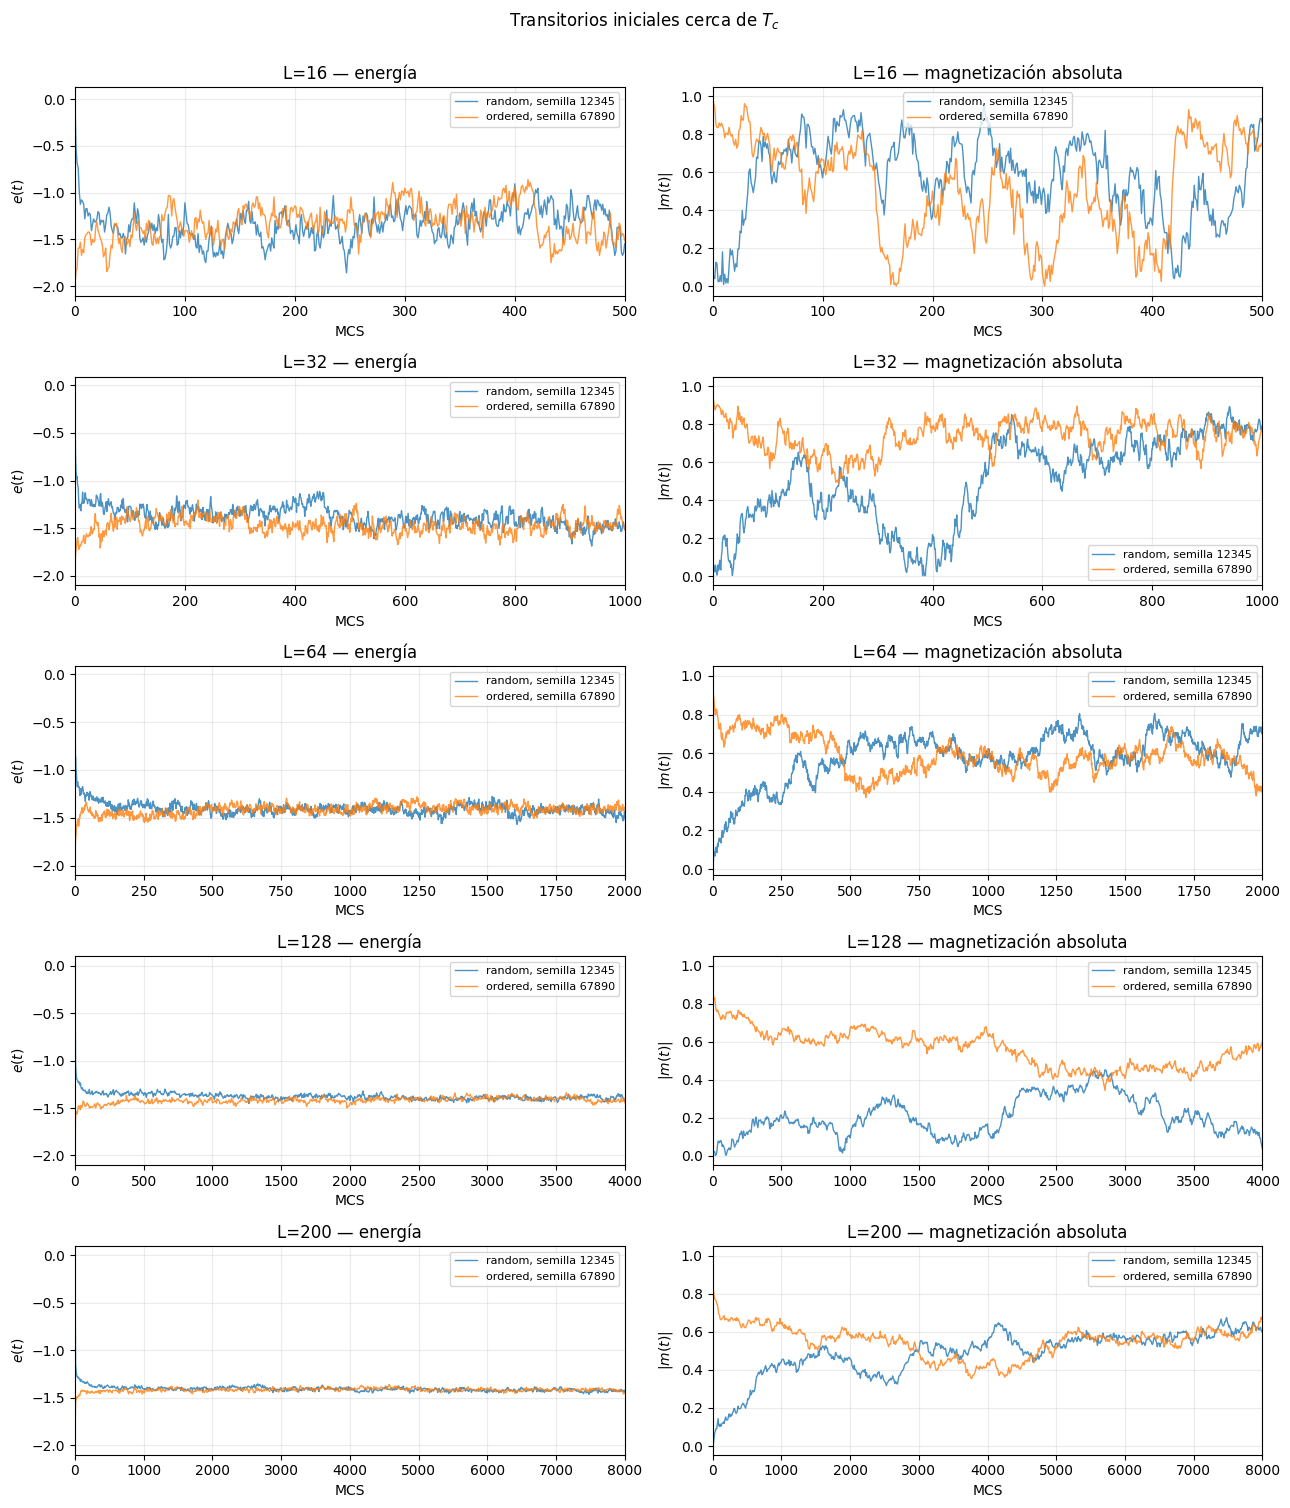

In [11]:
sizes_with_data = [L for L in L_VALUES if runs_by_L.get(L)]

if not sizes_with_data:
    print("No hay series cerca de Tc para mostrar.")
else:
    fig, axes = plt.subplots(len(sizes_with_data), 2, figsize=(13, 3.0 * len(sizes_with_data)), squeeze=False)
    for row, L in enumerate(sizes_with_data):
        zoom = ZOOM_BY_L[L]
        for initial, selected in runs_by_L[L].items():
            df = load_series(selected["path"])
            part = df[df["MCS"] <= zoom]
            label = f"{initial}, semilla {selected['seed']}"
            axes[row, 0].plot(part["MCS"], part["Energy_per_spin"], lw=1.0, alpha=0.8, label=label)
            axes[row, 1].plot(part["MCS"], part["Mag_per_spin"].abs(), lw=1.0, alpha=0.8, label=label)
        axes[row, 0].set(title=f"L={L} — energía", xlabel="MCS", ylabel=r"$e(t)$", xlim=(0, zoom))
        axes[row, 1].set(title=f"L={L} — magnetización absoluta", xlabel="MCS", ylabel=r"$|m(t)|$", xlim=(0, zoom))
        for ax in axes[row]:
            ax.grid(alpha=0.25)
            ax.legend(fontsize=8)
    fig.suptitle(r"Transitorios iniciales cerca de $T_c$", y=1.002)
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / "transitorios_todos_los_tamanos.png", dpi=180, bbox_inches="tight")
    plt.show()


### 7.2. Autocorrelaciones y tamaño del sistema

La siguiente tabla utiliza **un descarte provisional del 10 % de cada serie**, solamente para explorar la dependencia con $L$. No lo interpretamos como una justificación de termalización: el descarte final se elegirá revisando los transitorios y comparaciones de promedios.

Para cada serie se estiman $\tau_{\mathrm{int},E}$ y $\tau_{\mathrm{int},|m|}$ con la misma ventana autoconsistente de la sección 4. La columna `N_eff aprox.` estima cuántas observaciones independientes equivalentes contiene el tramo analizado. `Evaluación` advierte si la ventana quedó truncada o hay pocas muestras efectivas; en esos casos los resultados **no deben utilizarse como estimaciones definitivas**.

**Atención:** una estimación de $\tau_{\mathrm{int}}$ puede estar sesgada a la baja si la trayectoria es corta respecto de los modos lentos. Aumentar $L$ sin aumentar suficientemente la duración no garantiza una estimación fiable.


In [12]:
DISCARD_FRACTION_PILOT = 0.10  # Solo orientativo; NO un criterio definitivo.
MAX_ACF_LAG_MCS = 100_000        # Límite computacional amplio; no fija el tiempo de correlación.
MIN_NEFF_PILOT = 50              # Umbral orientativo para advertir poca estadística.

all_size_rows = []
for L in L_VALUES:
    for initial, selected in runs_by_L[L].items():
        df_full, dt = regular_series(selected["path"])
        total_mcs = int(df_full["MCS"].iloc[-1])
        discard_mcs = int(np.floor(total_mcs * DISCARD_FRACTION_PILOT / dt) * dt)
        df = df_full[df_full["MCS"] >= discard_mcs]
        if len(df) < 50:
            print(f"Serie demasiado corta para L={L}, {initial}")
            continue
        for obs, x in {
            "e": df["Energy_per_spin"].to_numpy(),
            "|m|": df["Mag_per_spin"].abs().to_numpy(),
        }.items():
            try:
                max_lag = min(len(x) // 4, MAX_ACF_LAG_MCS // dt)
                if max_lag < 5:
                    raise ValueError("Retardo máximo insuficiente")
                rho = autocorrelation_fft(x, max_lag=max_lag)
                tau_steps, window, window_ok = integrated_time(rho)
                neff = len(x) / (2 * tau_steps)
                warnings = []
                if not window_ok:
                    warnings.append("ventana truncada")
                if neff < MIN_NEFF_PILOT:
                    warnings.append("N_eff bajo")
                assessment = ", ".join(warnings) if warnings else "exploratorio"
                all_size_rows.append({
                    "L": L, "Inicial": initial, "Observable": obs,
                    "MCS totales": total_mcs, "Descarte piloto": discard_mcs,
                    "Promedio": x.mean(),
                    "Error aprox.": np.sqrt(2 * tau_steps * np.var(x, ddof=1) / len(x)),
                    "tau_int (MCS)": tau_steps * dt,
                    "N_eff aprox.": neff,
                    "Evaluación": assessment,
                })
            except ValueError as exc:
                print(f"No se pudo estimar L={L}, {initial}, {obs}: {exc}")

size_summary = pd.DataFrame(all_size_rows)
if size_summary.empty:
    print("Faltan series suficientemente largas para el resumen por tamaños.")
else:
    display(size_summary.round({"Promedio": 5, "Error aprox.": 5,
                                "tau_int (MCS)": 2, "N_eff aprox.": 1}))


,L,Inicial,Observable,MCS totales,Descarte piloto,Promedio,Error aprox.,tau_int (MCS),N_eff aprox.,Evaluación
0,16,random,e,20000,2000,-1.43269,0.00949,24.57,366.3,exploratorio
1,16,random,|m|,20000,2000,0.68176,0.01546,46.88,192.0,exploratorio
2,16,ordered,e,20000,2000,-1.45817,0.00745,16.76,536.9,exploratorio
3,16,ordered,|m|,20000,2000,0.72116,0.01308,47.02,191.4,exploratorio
4,32,random,e,20000,2000,-1.43448,0.00861,70.13,128.3,exploratorio
5,32,random,|m|,20000,2000,0.64598,0.03494,310.61,29.0,N_eff bajo
6,32,ordered,e,20000,2000,-1.43813,0.00751,58.37,154.2,exploratorio
7,32,ordered,|m|,20000,2000,0.66710,0.02269,165.27,54.5,exploratorio
8,64,random,e,100000,10000,-1.42621,0.00287,140.54,320.2,exploratorio
9,64,random,|m|,100000,10000,0.60963,0.01524,430.47,104.5,exploratorio


### 7.3. Evolución de los tiempos integrados con $L$

La figura permite visualizar el *critical slowing down* sin ajustar todavía un exponente dinámico $z$ (la guía no lo solicita). Las curvas son **orientativas** hasta confirmar que cada serie está equilibrada y tiene suficiente longitud en comparación con sus tiempos de autocorrelación.


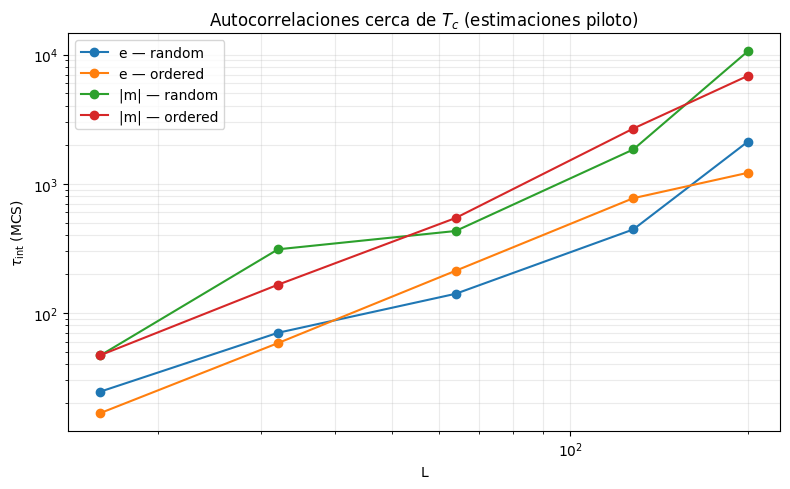

In [13]:
if size_summary.empty:
    print("Todavía no hay tiempos de autocorrelación para graficar.")
else:
    fig, ax = plt.subplots(figsize=(8, 5))
    for observable in ["e", "|m|"]:
        for initial in ["random", "ordered"]:
            d = size_summary[(size_summary["Observable"] == observable) &
                             (size_summary["Inicial"] == initial)].sort_values("L")
            if d.empty:
                continue
            ax.plot(d["L"], d["tau_int (MCS)"], "o-", label=f"{observable} — {initial}")
    ax.set(xlabel="L", ylabel=r"$\tau_{\mathrm{int}}$ (MCS)",
           title=r"Autocorrelaciones cerca de $T_c$ (estimaciones piloto)")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.grid(alpha=0.25, which="both")
    ax.legend()
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / "tau_integrado_vs_L_piloto.png", dpi=180)
    plt.show()


### 7.4. Estabilidad de las estimaciones para tamaños grandes

Para $L=16$ ya examinamos el efecto del descarte y la comparación por mitades en la sección 5. Ahora hacemos el mismo control, **sin nuevas simulaciones**, para $L=64$, $128$ y, cuando esté disponible, $200$. El caso $L=32$ puede ampliarse más adelante si necesitamos mejorar la estimación de su autocorrelación.

Probamos descartes del **5 %, 10 % y 20 %** de cada trayectoria. No son criterios físicos de termalización; sirven para comprobar si los promedios y $\tau_{\mathrm{int}}$ presentan una dependencia sistemática del tramo inicial. Usamos las unidades reales de MCS: **si la serie se guardó cada 5 MCS, convertimos las autocorrelaciones estimadas en unidades de muestra a MCS**.

Los resultados correspondientes a distintos descartes usan tramos superpuestos de una misma trayectoria y **no son estimaciones independientes**. Un cambio pequeño entre descartes no demuestra por sí solo equilibrio. También advertimos cuando la ventana de integración de la autocorrelación alcanza el retardo máximo o si la cantidad efectiva de muestras es baja.


In [14]:
# Control compacto para L grandes. Se incorpora L=200 automáticamente cuando existan sus CSV.
STABILITY_SIZES = [64, 128, 200]
DISCARD_FRACTIONS = [0.05, 0.10, 0.20]
STABILITY_MAX_LAG_MCS = 100_000
STABILITY_MIN_NEFF = 50  # Advertencia orientativa, no criterio definitivo.

def estimate_correlated_mean(values, dt):
    """Promedio, error aproximado y tau_int; dt expresado en MCS."""
    values = np.asarray(values, dtype=float)
    if len(values) < 50:
        raise ValueError("Muy pocas observaciones")
    max_lag = min(len(values) // 4, STABILITY_MAX_LAG_MCS // dt)
    if max_lag < 5:
        raise ValueError("Retardo máximo insuficiente")
    rho = autocorrelation_fft(values, max_lag=max_lag)
    tau_steps, window, window_ok = integrated_time(rho)
    neff = len(values) / (2.0 * tau_steps)
    se = np.sqrt(2.0 * tau_steps * np.var(values, ddof=1) / len(values))
    return {
        "Promedio": values.mean(),
        "Error aprox.": se,
        "tau_int (MCS)": tau_steps * dt,
        "Ventana (MCS)": window * dt,
        "N_eff aprox.": neff,
        "Ventana OK": window_ok,
    }

stability_rows = []
for L in STABILITY_SIZES:
    for initial, selected in runs_by_L.get(L, {}).items():
        df_full, dt = regular_series(selected["path"])
        max_mcs = int(df_full["MCS"].iloc[-1])
        for fraction in DISCARD_FRACTIONS:
            discard_mcs = int(np.ceil((fraction * max_mcs) / dt) * dt)
            part = df_full[df_full["MCS"] >= discard_mcs]
            for obs, x in {
                "e": part["Energy_per_spin"].to_numpy(),
                "|m|": part["Mag_per_spin"].abs().to_numpy(),
            }.items():
                try:
                    result = estimate_correlated_mean(x, dt)
                    stability_rows.append({
                        "L": L, "Inicial": initial, "Observable": obs,
                        "Descarte (%)": round(100 * fraction),
                        "Descarte (MCS)": discard_mcs,
                        **result,
                    })
                except ValueError as exc:
                    print(f"L={L}, {initial}, {obs}, descarte {fraction:.0%}: {exc}")

stability_large = pd.DataFrame(stability_rows)
if stability_large.empty:
    print("Aún no hay series suficientes de L=64, 128 o 200.")
else:
    cols = ["L", "Inicial", "Observable", "Descarte (%)", "Promedio",
            "Error aprox.", "tau_int (MCS)", "N_eff aprox.", "Ventana OK"]
    display(stability_large[cols].round({
        "Promedio": 5, "Error aprox.": 5,
        "tau_int (MCS)": 1, "N_eff aprox.": 1,
    }))
    problematic = stability_large[(~stability_large["Ventana OK"]) | (
        stability_large["N_eff aprox."] < STABILITY_MIN_NEFF)]
    if not problematic.empty:
        print("Advertencia: algunas estimaciones tienen ventana truncada o N_eff < 50.")


,L,Inicial,Observable,Descarte (%),Promedio,Error aprox.,tau_int (MCS),N_eff aprox.,Ventana OK
0,64,random,e,5,-1.42616,0.00290,149.8,317.2,True
1,64,random,|m|,5,0.60880,0.01514,441.9,107.5,True
2,64,random,e,10,-1.42621,0.00287,140.5,320.2,True
3,64,random,|m|,10,0.60963,0.01524,430.5,104.5,True
4,64,random,e,20,-1.42581,0.00316,148.8,268.9,True
5,64,random,|m|,20,0.60670,0.01644,430.1,93.0,True
6,64,ordered,e,5,-1.42496,0.00340,202.9,234.1,True
7,64,ordered,|m|,5,0.60056,0.01739,544.7,87.2,True
8,64,ordered,e,10,-1.42443,0.00359,211.9,212.3,True
9,64,ordered,|m|,10,0.59799,0.01807,542.8,82.9,True


Advertencia: algunas estimaciones tienen ventana truncada o N_eff < 50.


### 7.5. Comparación de las dos mitades de cada serie

Tomamos el tramo posterior a un **descarte provisional del 10 %** y lo dividimos en dos mitades *no superpuestas*. Comparamos los promedios y las estimaciones de $\tau_{\mathrm{int}}$ de energía y $|m|$. Mostramos una diferencia normalizada $z_{\mathrm{mitades}}=|\overline A_1-\overline A_2|/\sqrt{\mathrm{SE}_1^2+\mathrm{SE}_2^2}$ como diagnóstico **orientativo**, no como prueba formal de estacionariedad: las mitades son contiguas y las incertidumbres de $\tau_{\mathrm{int}}$ pueden ser grandes.

Buscamos **derivas persistentes** y estimaciones extremadamente discordantes, no una coincidencia exacta entre segmentos. Si aparecen problemas, revisaremos la duración de la serie y, si hace falta, haremos otra realización con diferente semilla antes de fijar parámetros de producción.


In [15]:
HALVES_DISCARD_FRACTION = 0.10
halves_large_rows = []

for L in STABILITY_SIZES:
    for initial, selected in runs_by_L.get(L, {}).items():
        df_full, dt = regular_series(selected["path"])
        final_mcs = int(df_full["MCS"].iloc[-1])
        discard_mcs = int(np.ceil(HALVES_DISCARD_FRACTION * final_mcs / dt) * dt)
        tail = df_full[df_full["MCS"] >= discard_mcs]
        half = len(tail) // 2
        if half < 50:
            print(f"L={L}, {initial}: serie corta para analizar por mitades")
            continue
        for obs, series in {
            "e": tail["Energy_per_spin"],
            "|m|": tail["Mag_per_spin"].abs(),
        }.items():
            x = series.to_numpy()
            try:
                first = estimate_correlated_mean(x[:half], dt)
                second = estimate_correlated_mean(x[half:], dt)
            except ValueError as exc:
                print(f"L={L}, {initial}, {obs}: {exc}")
                continue
            combined_se = np.hypot(first["Error aprox."], second["Error aprox."])
            z = abs(first["Promedio"] - second["Promedio"]) / combined_se if combined_se > 0 else np.nan
            halves_large_rows.append({
                "L": L, "Inicial": initial, "Observable": obs,
                "Prom. mitad 1": first["Promedio"],
                "Prom. mitad 2": second["Promedio"],
                "Error mitad 1": first["Error aprox."],
                "Error mitad 2": second["Error aprox."],
                "Diferencia / error": z,
                "tau mitad 1 (MCS)": first["tau_int (MCS)"],
                "tau mitad 2 (MCS)": second["tau_int (MCS)"],
                "N_eff mitad 1": first["N_eff aprox."],
                "N_eff mitad 2": second["N_eff aprox."],
                "Ventanas OK": first["Ventana OK"] and second["Ventana OK"],
            })

halves_large = pd.DataFrame(halves_large_rows)
if halves_large.empty:
    print("No hay suficientes series para comparar por mitades.")
else:
    display(halves_large.round({
        "Prom. mitad 1": 5, "Prom. mitad 2": 5,
        "Error mitad 1": 5, "Error mitad 2": 5,
        "Diferencia / error": 2,
        "tau mitad 1 (MCS)": 1, "tau mitad 2 (MCS)": 1,
        "N_eff mitad 1": 1, "N_eff mitad 2": 1,
    }))
    if (~halves_large["Ventanas OK"]).any():
        print("Advertencia: alguna ventana de autocorrelación quedó truncada.")
    if (halves_large["Diferencia / error"] > 2.5).any():
        print("Atención: alguna diferencia entre mitades merece una revisión más detallada.")


,L,Inicial,Observable,Prom. mitad 1,Prom. mitad 2,Error mitad 1,Error mitad 2,Diferencia / error,tau mitad 1 (MCS),tau mitad 2 (MCS),N_eff mitad 1,N_eff mitad 2,Ventanas OK
0,64,random,e,-1.42406,-1.42836,0.00397,0.00418,0.75,131.5,152.4,171.1,147.7,True
1,64,random,|m|,0.60364,0.61562,0.02048,0.02245,0.39,387.5,469.5,58.1,47.9,True
2,64,ordered,e,-1.42229,-1.42657,0.00502,0.00511,0.60,215.7,207.9,104.3,108.2,True
3,64,ordered,|m|,0.59471,0.60126,0.02973,0.01972,0.18,805.2,297.4,27.9,75.7,True
4,128,random,e,-1.42300,-1.41589,0.00166,0.00239,2.44,252.8,507.5,267.0,133.0,True
5,128,random,|m|,0.59164,0.53953,0.01264,0.01998,2.20,1128.8,1621.3,59.8,41.6,True
6,128,ordered,e,-1.42339,-1.41630,0.00187,0.00370,1.71,332.8,1057.6,202.9,63.8,True
7,128,ordered,|m|,0.58734,0.51501,0.01364,0.03156,2.10,1234.0,2104.4,54.7,32.1,True
8,200,random,e,-1.41381,-1.42115,0.00216,0.00090,3.13,2718.0,582.0,82.8,386.6,True
9,200,random,|m|,0.47506,0.56424,0.02935,0.01180,2.82,6881.5,3709.9,32.7,60.6,True


Atención: alguna diferencia entre mitades merece una revisión más detallada.


### Siguiente paso

Los resultados a $T_c$ permiten observar el crecimiento de las autocorrelaciones con $L$. La diferencia entre mitades de algunas corridas grandes y la dispersión de $\tau_{\mathrm{int}}$ indican que **las duraciones preliminares no deben confundirse con precisión de producción**. A continuación examinamos la relajación fuera de la región crítica y cerramos con un protocolo de partida, indicando qué está confirmado y qué deberá ajustarse según los errores de las mediciones definitivas.

## 8. Comprobación fuera de la temperatura crítica: $L=200$

A $T_c$ el frenado crítico es fuerte, pero **eso no garantiza** que sea la condición inicial que más tarda en relajarse para todas las temperaturas. En particular, a $T=1.5<T_c$ una configuración aleatoria puede necesitar tiempo para eliminar interfaces y ordenar dominios; a $T=3.0>T_c$ esperamos una relajación relativamente rápida.

Analizamos las corridas guardadas en `preliminar_data/`, sin inventar resultados para los archivos que falten. Para cada temperatura mostramos las trayectorias desde condiciones iniciales independientes, una ampliación del transitorio y una comprobación de estabilidad de las medidas. Los cortes del 5 %, 10 % y 20 % son **diagnósticos**, no una selección automática de termalización.

In [16]:
L_OFFCRITICAL = 200
OFFCRITICAL_TEMPS = [1.5, 3.0]
OFFCRITICAL_SEEDS = {"random": 12345, "ordered": 67890}
T_TOL_OFF = 5e-4

runs_offcritical = {}
missing_offcritical = []
for T in OFFCRITICAL_TEMPS:
    runs_offcritical[T] = {}
    for initial, seed in OFFCRITICAL_SEEDS.items():
        candidates = files[
            (files["L"] == L_OFFCRITICAL)
            & ((files["T"] - T).abs() < T_TOL_OFF)
            & (files["initial"] == initial)
            & (files["seed"] == seed)
        ]
        if candidates.empty:
            missing_offcritical.append((T, initial, seed))
        else:
            runs_offcritical[T][initial] = candidates.iloc[0].to_dict()

inventory_off = pd.DataFrame([
    {"L": L_OFFCRITICAL, "T": T, "Inicial": initial,
     "Semilla": seed, "Archivo": "Disponible" if initial in runs_offcritical[T] else "FALTA"}
    for T in OFFCRITICAL_TEMPS for initial, seed in OFFCRITICAL_SEEDS.items()
])
display(inventory_off)

if missing_offcritical:
    print("Corridas faltantes (si aún no están en la carpeta local):")
    for T, initial, seed in missing_offcritical:
        print(f"  ./ising_sim {seed} --prelim {L_OFFCRITICAL} {T} {initial} 100000 10")
else:
    print("Están disponibles las cuatro corridas de contraste.")

,L,T,Inicial,Semilla,Archivo
0,200,1.5,random,12345,Disponible
1,200,1.5,ordered,67890,Disponible
2,200,3.0,random,12345,Disponible
3,200,3.0,ordered,67890,Disponible


Están disponibles las cuatro corridas de contraste.


### 8.1. Relajación desde las dos condiciones iniciales

La figura de la izquierda muestra toda la trayectoria; la de la derecha amplía el inicio. **No exigimos que dos trayectorias independientes coincidan**, sino que sus distribuciones estacionarias sean compatibles. Usamos $|m|$ para no confundir cambios de signo global con pérdida de orden.

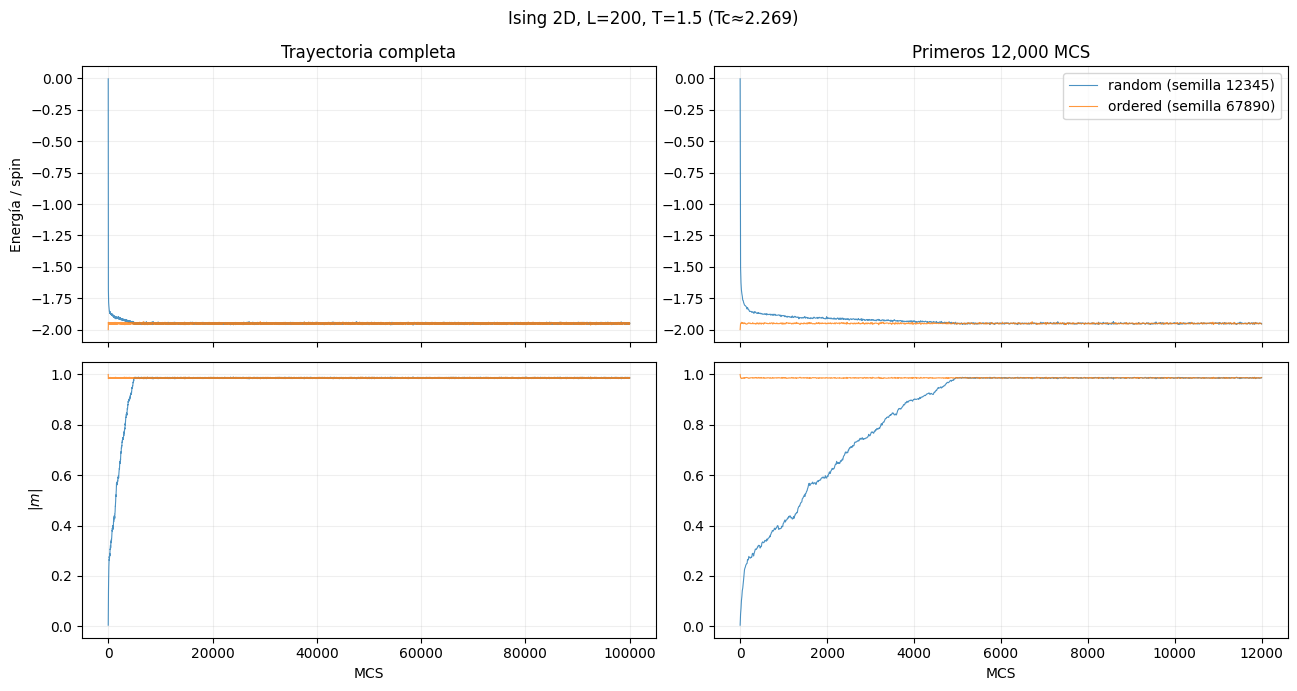

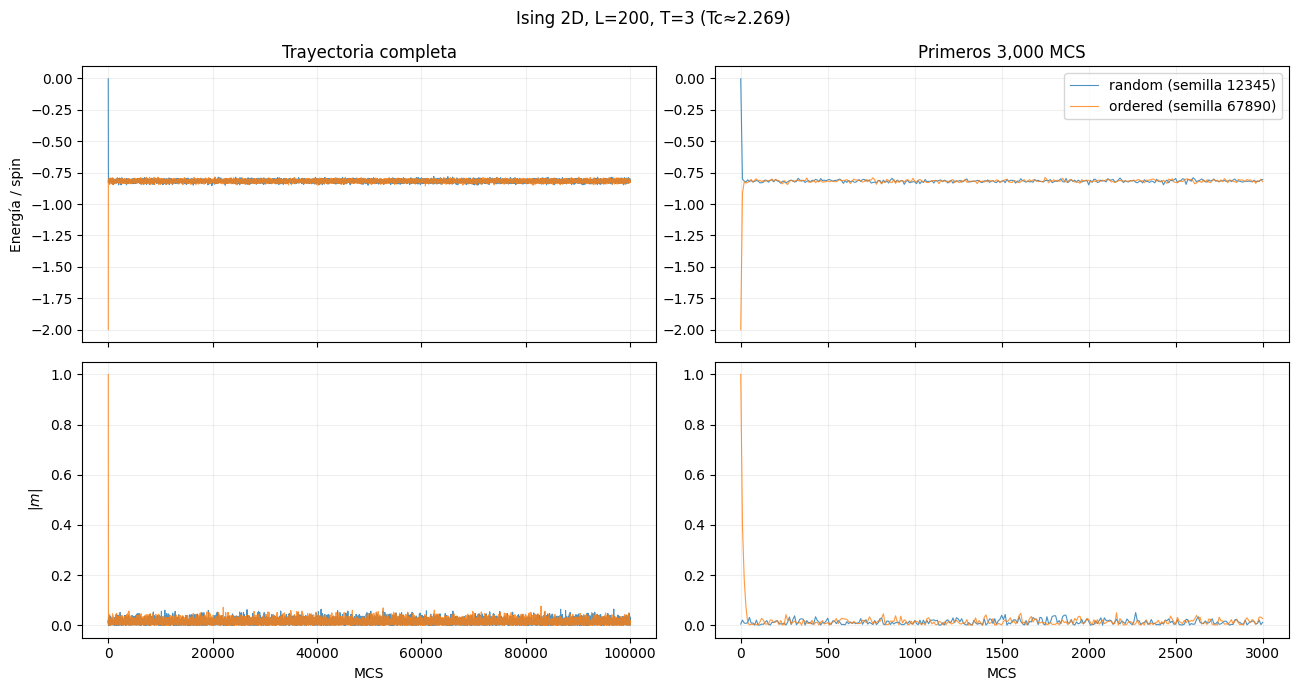

In [17]:
ZOOM_OFF_MCS = {1.5: 12_000, 3.0: 3_000}
for T, these_runs in runs_offcritical.items():
    if not these_runs:
        print(f"No hay archivos para T={T:g}")
        continue
    fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex="col")
    for initial, selected in these_runs.items():
        df, dt = regular_series(selected["path"])
        label = f"{initial} (semilla {selected['seed']})"
        for col in (0, 1):
            plot_df = df if col == 0 else df[df["MCS"] <= ZOOM_OFF_MCS[T]]
            axes[0, col].plot(plot_df["MCS"], plot_df["Energy_per_spin"], lw=0.8, alpha=0.8, label=label)
            axes[1, col].plot(plot_df["MCS"], plot_df["Mag_per_spin"].abs(), lw=0.8, alpha=0.8, label=label)
    for col, title in enumerate(["Trayectoria completa", f"Primeros {ZOOM_OFF_MCS[T]:,} MCS"]):
        axes[0, col].set_title(title)
        axes[1, col].set_xlabel("MCS")
        axes[0, col].grid(alpha=0.2)
        axes[1, col].grid(alpha=0.2)
    axes[0, 0].set_ylabel("Energía / spin")
    axes[1, 0].set_ylabel(r"$|m|$")
    axes[0, 1].legend(loc="best")
    fig.suptitle(f"Ising 2D, L={L_OFFCRITICAL}, T={T:g} (Tc≈{TC_EXACT:.3f})")
    fig.tight_layout()
    if SAVE_FIGURES:
        GRAPH_DIR.mkdir(exist_ok=True)
        fig.savefig(GRAPH_DIR / f"prelim_offcritical_L={L_OFFCRITICAL}_T={T:g}.png", dpi=200)
    plt.show()

### 8.2. Estabilidad de los promedios, autocorrelaciones y dos mitades

Estimamos el error aproximado usando el tiempo integrado del **propio observable**, con el intervalo real de guardado en MCS. La comparación entre mitades después del 10 % de descarte sirve para detectar derivas persistentes; la diferencia normalizada no es un test formal porque $\tau_{\mathrm{int}}$ también es incierto. En el régimen ordenado es útil controlar $|m|$ además de $e$, especialmente al partir de una configuración aleatoria.

**Resolución temporal:** en estas corridas se guarda un punto cada 10 MCS. El estimador de autocorrelación integrada parte de $\tau_{\mathrm{int}}=1/2$ en unidades de muestras, por lo que su mínima estimación positiva en MCS es $5$. Si obtenemos $\tau_{\mathrm{int}}\simeq5$ MCS, esto no demuestra que el tiempo intrínseco de la dinámica sea 5 MCS: significa que las correlaciones de la serie *almacenada* ya son muy pequeñas. Este muestreo permite comparar promedios pero no resolver con precisión autocorrelaciones que decaen mucho más rápido que 10 MCS.


In [18]:
OFF_DISCARD_FRACTIONS = [0.05, 0.10, 0.20]
rows_off = []
rows_halves_off = []
for T, these_runs in runs_offcritical.items():
    for initial, selected in these_runs.items():
        df_full, dt = regular_series(selected["path"])
        last_mcs = int(df_full["MCS"].iloc[-1])
        for frac in OFF_DISCARD_FRACTIONS:
            discard_mcs = int(np.ceil(frac * last_mcs / dt) * dt)
            part = df_full[df_full["MCS"] >= discard_mcs]
            if len(part) < 50:
                print(f"T={T}, {initial}: insuficientes mediciones para descarte {frac}")
                continue
            for observable, values in {
                "e": part["Energy_per_spin"].to_numpy(),
                "|m|": part["Mag_per_spin"].abs().to_numpy(),
            }.items():
                try:
                    est = estimate_correlated_mean(values, dt)
                except ValueError as exc:
                    print(f"T={T:g}, {initial}, {observable}: {exc}")
                    continue
                rows_off.append({
                    "T": T, "Inicial": initial, "Descarte (%)": int(frac * 100),
                    "Observable": observable, **est,
                })
                if frac == 0.10:
                    middle = len(values) // 2
                    if middle >= 50:
                        try:
                            first = estimate_correlated_mean(values[:middle], dt)
                            second = estimate_correlated_mean(values[middle:], dt)
                        except ValueError as exc:
                            print(f"T={T:g}, {initial}, {observable}, mitades: {exc}")
                            continue
                        combined_se = np.hypot(first["Error aprox."], second["Error aprox."])
                        rows_halves_off.append({
                            "T": T, "Inicial": initial, "Observable": observable,
                            "Prom. mitad 1": first["Promedio"],
                            "Prom. mitad 2": second["Promedio"],
                            "Diferencia / error": abs(first["Promedio"] - second["Promedio"]) / combined_se
                            if combined_se > 0 else np.nan,
                            "tau mitad 1 (MCS)": first["tau_int (MCS)"],
                            "tau mitad 2 (MCS)": second["tau_int (MCS)"],
                            "Ventanas OK": first["Ventana OK"] and second["Ventana OK"],
                        })

offcritical_summary = pd.DataFrame(rows_off)
offcritical_halves = pd.DataFrame(rows_halves_off)

if not offcritical_summary.empty:
    display(offcritical_summary.round({
        "Promedio": 5, "Error aprox.": 5,
        "tau_int (MCS)": 1, "N_eff aprox.": 1,
    }))
else:
    print("No hay resultados fuera de Tc para analizar.")

if not offcritical_halves.empty:
    display(offcritical_halves.round({
        "Prom. mitad 1": 5, "Prom. mitad 2": 5,
        "Diferencia / error": 2, "tau mitad 1 (MCS)": 1,
        "tau mitad 2 (MCS)": 1,
    }))
    flagged = offcritical_halves[
        (offcritical_halves["Diferencia / error"] > 2.5) | ~offcritical_halves["Ventanas OK"]
    ]
    if not flagged.empty:
        print("Advertencia: algunas mitades o ventanas deben revisarse antes de fijar el protocolo.")

,T,Inicial,Descarte (%),Observable,Promedio,Error aprox.,tau_int (MCS),Ventana (MCS),N_eff aprox.,Ventana OK
0,1.5,random,5,e,-1.95107,0.00003,5.1,30,9401.2,True
1,1.5,random,5,|m|,0.98648,0.00001,5.1,30,9298.0,True
2,1.5,random,10,e,-1.95105,0.00004,5.0,30,8928.0,True
3,1.5,random,10,|m|,0.98648,0.00001,5.1,30,8805.3,True
4,1.5,random,20,e,-1.95108,0.00004,5.0,30,8001.0,True
5,1.5,random,20,|m|,0.98649,0.00001,5.1,30,7852.9,True
6,1.5,ordered,5,e,-1.95113,0.00003,5.0,30,9489.9,True
7,1.5,ordered,5,|m|,0.98650,0.00001,5.1,30,9308.8,True
8,1.5,ordered,10,e,-1.95112,0.00003,5.0,30,8965.7,True
9,1.5,ordered,10,|m|,0.98650,0.00001,5.1,30,8798.3,True


,T,Inicial,Observable,Prom. mitad 1,Prom. mitad 2,Diferencia / error,tau mitad 1 (MCS),tau mitad 2 (MCS),Ventanas OK
0,1.5,random,e,-1.95101,-1.95109,1.20,5.0,5.5,True
1,1.5,random,|m|,0.98647,0.98649,1.04,5.0,5.6,True
2,1.5,ordered,e,-1.95116,-1.95107,1.24,5.0,5.4,True
3,1.5,ordered,|m|,0.98652,0.98648,1.64,5.0,5.5,True
4,3.0,random,e,-0.81744,-0.81731,0.61,5.4,5.2,True
5,3.0,random,|m|,0.01350,0.01345,0.21,7.1,7.0,True
6,3.0,ordered,e,-0.81737,-0.81729,0.38,5.1,5.4,True
7,3.0,ordered,|m|,0.01358,0.01337,0.76,7.4,8.6,True


## 9. Balance y protocolo para las simulaciones definitivas

### 9.1. Validaciones concluidas

- **Modelo:** Ising ferromagnético en red cuadrada $L\times L$, primeros vecinos, condiciones periódicas, $J=k_B=1$.
- **Dinámica:** Metropolis de *spin flip* individual, con $N=L^2$ sitios escogidos **con reemplazo** por barrido (MCS). La regla de aceptación satisface balance detallado para la distribución de Boltzmann.
- **Consistencia y validación física:** la energía y magnetización incrementales coinciden con el cálculo directo; el programa reproduce promedios exactos para $L=4$ en temperaturas representativas. Esto valida la implementación básica, **no** la precisión de cada simulación.
- **Observables:** se medirán $m$, $|m|$, $m^2$, $m^4$, $e$, $e^2$, con $e=H/N$. A campo nulo distinguir $\chi=(N/T)(\langle m^2\rangle-\langle m\rangle^2)$ de $\chi_{|m|}=(N/T)(\langle m^2\rangle-\langle|m|\rangle^2)$; a $B=0$, por simetría exacta del ensamble finito, $\langle m\rangle=0$ y por tanto $\chi=(N/T)\langle m^2\rangle$ en equilibrio. No confundir estimadores ni atribuir respuesta lineal a $\chi_{|m|}$.

### 9.2. Hallazgos preliminares

- La relajación de $e$ puede ser más rápida que la de $|m|$; por eso **ambos** observables intervienen en el diagnóstico de termalización.
- Cerca de $T_c=2/\ln(1+\sqrt2)$, $\tau_{\mathrm{int}}$ aumenta fuertemente con $L$ (*critical slowing down*), sobre todo para $|m|$.
- Para $L=128$ y $200$ se observan diferencias entre mitades y dispersión entre estimaciones de $\tau_{\mathrm{int}}$. Esto indica **incertidumbre estadística de los pilotos**; no se debe afirmar que el equilibrio o los tiempos estén demostrados con precisión.
- Para $L=200$ a **$T=1.5$**, una configuración aleatoria desarrolla orden mediante crecimiento de dominios y $|m|$ se acerca a su meseta aproximadamente después de $5\times10^3$ MCS; la energía se relaja antes. Tras descartar $10^4$ MCS, los promedios de condiciones iniciales distintas concuerdan: $\langle e\rangle\approx-1.9511$ y $\langle|m|\rangle\approx0.9865$, sin deriva relevante entre mitades.
- Para $L=200$ a **$T=3.0$**, ambas condiciones iniciales se relajan rápidamente; luego del descarte se obtiene $\langle e\rangle\approx-0.8173$ y $\langle|m|\rangle\approx0.0135$, con estabilidad entre mitades. 
- **Limitación temporal fuera de $T_c$:** como se guardó cada 10 MCS, los $\tau_{\mathrm{int}}$ estimados cercanos a 5 MCS son esencialmente el piso de resolución del estimador; *no* deben presentarse como medidas precisas del tiempo físico de autocorrelación. La decisión relevante es que, al intervalo de almacenamiento elegido, las muestras consecutivas tienen correlación pequeña.

### 9.3. Decisiones y reglas para producción

1. **Configuraciones iniciales:** por defecto aleatorias, con semillas diferentes para realizaciones independientes. Las inicializaciones ordenadas se reservan para validación de termalización. Si la secuencia de temperaturas utiliza herencia de configuración, registrarla y validarla explícitamente; no confundir esa herencia con independencia estadística entre temperaturas.
2. **Región crítica:** simular primero una grilla de temperaturas moderada para los cinco tamaños; refinar **solamente** alrededor de los máximos de $\chi$, $C$, cruces de Binder y puntos de inflexión, según corresponda. No recuperar automáticamente la antigua grilla de 92 temperaturas.
3. **Termalización:** como **valores de arranque conservadores para $T\simeq T_c$** (no garantías universales), usar tiempos de descarte aproximadamente diez veces la estimación alta de $\tau_{\mathrm{int},|m|}$ para cada tamaño; confirmar con independencia de condición inicial y estabilidad de los promedios. Fuera de $T_c$, en particular $T=1.5$ con inicio aleatorio, prevalece la relajación observada en la sección 8.
4. **Duración de producción:** no reutilizar `1000 MCS` de termalización ni `3000` medidas separadas por `50 MCS`. Elegir una duración inicial que produzca **como objetivo de planificación** $N_{\mathrm{eff},|m|}\gtrsim200$ cerca de $T_c$: $t_{\mathrm{med}}\gtrsim 2\tau_{\mathrm{int},|m|}N_{\mathrm{eff}}$. **No es una garantía** de error pequeño para $C$, Binder, máximos o exponentes; éstos deben validarse con incertidumbres reales y ampliación selectiva de corridas.
5. **Guardado y errores:** guardar observaciones regulares con intervalo mucho menor que $\tau_{\mathrm{int}}$ (no hace falta independencia entre mediciones), y/o acumular bloques identificables por corrida. Calcular momentos y observables derivados con **bloques más largos que los tiempos de autocorrelación** y estimar errores mediante jackknife por bloques o realizaciones independientes. Conservar los datos suficientes para recalcular errores; guardar solo promedios por temperatura **no** basta.
6. **Reproducibilidad:** registrar $L,T,J,B$, semilla, condición inicial, MCS descartados, MCS medidos e intervalo de guardado. No sobrescribir corridas por accidente.
7. **Campo no nulo, apartado (f):** requiere una grilla adicional de $B/J$ para temperaturas por encima, por debajo y cerca de $T_c$, y atención a la relajación/inversiones de magnetización; el protocolo a campo nulo no se traslada automáticamente.

### 9.4. Escala inicial de recursos *cerca de* $T_c$

Los números de la tabla siguiente **no son resultados de una optimización**: son redondeos prudentes basados en la escala superior de $\tau_{\mathrm{int},|m|}$ observada en los pilotos (dos condiciones iniciales). Se usarán **como punto de partida** para planificar corridas a $T_c$, sujeto a la sección 8 y a errores medidos en producción.

| $L$ | Referencia alta de $\tau_{\mathrm{int},|m|}$ (MCS) | Descarte inicial a $T_c$ (MCS) | Medición inicial para $N_{\mathrm{eff}}\sim200$ (MCS) |
|---:|---:|---:|---:|
| 16 | $\sim 50$ | 1 000 | 20 000 |
| 32 | $\sim 310$ | 4 000 | 130 000 |
| 64 | $\sim 550$ | 6 000 | 250 000 |
| 128 | $\sim 3 100$ | 35 000 | 1 300 000 |
| 200 | $\sim 11 000$ | 120 000 | 4 500 000 |

Estos valores se basan en $\tau_{\mathrm{int},|m|}$ y se proponen **para la región crítica**. No significan que las corridas de producción deban tener la misma longitud para todas las temperaturas ni que necesariamente haya que hacer millones de MCS en toda la grilla. Se verificará la precisión de $\chi_{|m|}$, $C$, momentos y Binder con análisis por bloques y realizaciones; las simulaciones se prolongarán **solo donde haga falta**. Cerca de $T_c$ las estimaciones de $\tau$ son ruidosas y pueden requerir márgenes adicionales.

### 9.5. Pendientes mínimos antes de lanzar producción

- **El contraste fuera de $T_c$ está completo:** están las cuatro corridas de $L=200$ en $T=1.5$ y $3.0$. Con inicio aleatorio a $T=1.5$, la relajación observada del orden de $5\times10^3$ MCS queda cubierta por un descarte de $10^4$ MCS en ese caso concreto; no extrapolar automáticamente este mínimo a cualquier tamaño, campo o temperatura.
- **Adaptar la producción de `main.cpp`**: todavía tiene la grilla de temperaturas y los números antiguos codificados. Habilitar semillas, grilla y duraciones controladas; guardar series o bloques de momentos suficientes para estimar errores de $\chi$, $C$ y Binder, además de promedios. Hacer una corrida piloto y comprobar que se pueden reconstruir observables e incertidumbres.
- **Limpiar cuidadosamente el repositorio**, después de respaldar o versionar las series preliminares que se quieren conservar: descartar resultados antiguos con energía inválida, viejas series/gráficos y el ejecutable generado. Reservar `analysis.ipynb` para el análisis definitivo.
- **Validación en producción:** una vez ejecutado el piloto, comprobar magnitudes físicas, estabilidad de los promedios, errores de bloques y la ubicación de la región pseudocrítica antes de realizar el barrido masivo.

**Criterio de cierre:** las pruebas exploratorias de termalización y autocorrelación quedan cerradas con esta notebook. Los tiempos de la tabla son **un protocolo inicial de planificación**, no una demostración de precisión ni una receta idéntica para cada temperatura. La producción estará lista para comenzar después de adaptar `main.cpp` y validar una corrida piloto con incertidumbres.

### 9.6. Conclusión breve para la entrega

Las comprobaciones sobre $L=16,32,64,128,200$ a $T_c$ muestran un aumento pronunciado de la autocorrelación integrada con $L$, especialmente para $|m|$, en concordancia con el *critical slowing down* de Metropolis. Las condiciones iniciales ordenadas y aleatorias alcanzan promedios compatibles, pero las series grandes presentan fluctuaciones lentas y estimaciones de $\tau_{\mathrm{int}}$ dispersas. Por ello, las simulaciones de producción deberán ser más largas cerca de la región crítica y sus incertidumbres deberán estimarse a partir de bloques o realizaciones independientes. El contraste adicional con $L=200$ a $T=1.5$ y $T=3.0$ confirma que la relajación depende de la temperatura y de la condición inicial: el crecimiento de dominios a baja temperatura puede retardar la magnetización aunque la energía se haya estabilizado. 

Se conservará Metropolis sin introducir algoritmos más complejos. Los tiempos de descarte y duración de la tabla anterior se utilizarán como valores **iniciales** para la región crítica y se corregirán, si hace falta, según las pruebas de producción; la grilla de temperaturas se refinara únicamente donde sea necesario para estimar máximos, cruces y exponentes con incertidumbres adecuadas.
